# Imports

In [1]:
%pip install tf2onnx
%pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 6.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 38.0 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [31]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from keras.utils import image_dataset_from_directory
from keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from keras.applications.resnet50 import ResNet50
from keras.optimizers import Adam
from keras.models import load_model
from keras import Model
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import kagglehub
import os
import shutil
import tf2onnx
import datetime
import onnx

# Dataset download

In [3]:
path = Path(kagglehub.dataset_download("ahmedmohamedabdallah/breastcancer"))
print(f"Path to dataset: {path}")

Path to dataset: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer


# Analysis and preprocessment

In [4]:
data = Path("/kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data")
print(os.listdir(data))

['Cancer', 'Negative']


In [5]:
classes = list(os.listdir(data))
cancer_data = Path(os.path.join(data, classes[0])) # Bibliography: [Ref.1]
no_cancer_data = Path(os.path.join(data, classes[1])) # Bibliography: [Ref.1]
print(f"Classes: {classes}")
print(f"Cancer images path: {cancer_data}")
print(f"No cancer images path: {no_cancer_data}")

Classes: ['Cancer', 'Negative']
Cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Cancer
No cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Negative


In [6]:
def check_formats(path_data_to_check: Path) -> dict:
    res = {}
    key_res = str(path_data_to_check).split("/")[-1]
    res[key_res] = []
    for image in os.listdir(path_data_to_check):
        _, img_format = image.split(".")
        if img_format not in res[key_res]:
            res[key_res].append(img_format)
    return res

cancer_formats = check_formats(cancer_data)
print(cancer_formats)
no_cancer_formats = check_formats(no_cancer_data)
print(no_cancer_formats)

{'Cancer': ['jpg']}
{'Negative': ['jpg']}


In [7]:
num_cancer = len(os.listdir(cancer_data))
print(f"Number cancer images: {num_cancer}")
num_no_cancer = len(os.listdir(no_cancer_data))
print(f"Number cancer images: {num_no_cancer}")

Number cancer images: 410
Number cancer images: 410


In [8]:
images = []
classes_labels = []

for class_name in os.listdir(data):
    class_path = Path(os.path.join(data, class_name))
    for image in class_path.iterdir():
        images.append(image)
        classes_labels.append(class_name)

paths_train, paths_temp, labels_train, labels_temps = train_test_split( # 80% train 20% test and validation
    images, classes_labels, train_size=0.8 # Bibliography: [Ref.2] and Bibliography: [Ref.3]
)

paths_val, paths_test, labels_val, labels_test = train_test_split( # 10% validation 10% test
    paths_temp, labels_temps, train_size=0.5 # Bibliography: [Ref.2] and Bibliography: [Ref.3]
)

print(f"Num images train: {len(paths_train)}")
print(f"Num images validation: {len(paths_val)}")
print(f"Num images test: {len(paths_test)}")

Num images train: 656
Num images validation: 82
Num images test: 82


In [9]:
dirs_to_create = [
    "train", "validation", "test", "train/Cancer", "validation/Cancer", "test/Cancer", "train/Negative", "validation/Negative", "test/Negative"
]

for folder in dirs_to_create:
    os.makedirs(folder, exist_ok=True) # Bibliography: [Ref.4]

In [10]:
def copy_images(images_paths: Path, labels: Path, destination: Path)-> None:
    for file in Path(os.path.join(destination, "Cancer")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    for file in Path(os.path.join(destination, "Negative")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    for image_path, label in zip(images_paths, labels): # Bibliography: [Ref.6]
        if label == "Cancer":
            shutil.copy(image_path, os.path.join(destination, "Cancer")) # Bibliography: [Ref.7]
        elif label == "Negative":
            shutil.copy(image_path, os.path.join(destination, "Negative")) # Bibliography: [Ref.7]

copy_images(paths_train, labels_train, Path("train"))
copy_images(paths_test, labels_test, Path("test"))
copy_images(paths_val, labels_val, Path("validation"))

In [11]:
train_dir = Path("/kaggle/working/train")
test_dir = Path("/kaggle/working/test")
val_dir = Path("/kaggle/working/validation")

train_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    train_dir,
    labels="inferred",
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224)
)
val_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    val_dir,
    labels="inferred",
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224)
)
test_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    test_dir,
    labels="inferred",
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224)
)

Found 656 files belonging to 2 classes.
Found 82 files belonging to 2 classes.
Found 82 files belonging to 2 classes.


# Architecture definition

In [12]:
base_model = ResNet50( # Bibliography: [Ref.9]
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False # Bibliography: [Ref.10]

input_layer = Input(shape=(224, 224, 3)) # Bibliography: [Ref.11]
base_model_layer = base_model(input_layer) # Bibliography: [Ref.9]
global_pooling_layer = GlobalAveragePooling2D()(base_model_layer) # Bibliography: [Ref.12]
dense_layer = Dense(1024, activation='relu')(global_pooling_layer) # Bibliography: [Ref.13]
dropout_layer = Dropout(0.5)(dense_layer) # Bibliography: [Ref.14]
dense_classification_layer = Dense(2, activation='softmax')(dropout_layer) # Bibliography: [Ref.13]

model = Model(inputs=input_layer, outputs=dense_classification_layer) # Bibliography: [Ref.15]

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [13]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,687,938 (97.99 MB)

 Trainable params: 2,100,226 (8.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [14]:
optimizer = Adam(learning_rate=0.001) # Bibliography: [Ref.16]
model.compile( # Bibliography: [Ref.17]
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy", # Bibliography: [Ref.18]
    metrics=["accuracy"]
)

In [15]:
early_stopping = EarlyStopping( # Bibliography: [Ref.19]
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)
os.makedirs("checkpoints", exist_ok=True)
model_checkpoint = ModelCheckpoint( # Bibliography: [Ref.20]
    Path("checkpoints/best_resnet.keras"),
    monitor="val_loss",
    save_best_only=True
)
reduce_lr = ReduceLROnPlateau( # Bibliography: [Ref.21]
    monitor="val_loss",
    patience=20,
    verbose=1
)

In [17]:
train_hist = model.fit( # Bibliography: [Ref.17]
    train_dataset,
    epochs=1000,
    validation_data=val_dataset,
    callbacks=[model_checkpoint, reduce_lr, early_stopping] # Bibliography: [Ref.22]
)

Epoch 1/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 2/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 1.0000 - loss: 8.0262e-04 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 3/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 4/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 1.0000 - loss: 8.3672e-04 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 5/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 1.0000 - loss: 8.6811e-04 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 6/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0.9878 - val_loss: 0.1065 - learning_rate: 1.0000e-24
Epoch 7/1000
21/21 ━━━━━━━━━━━━━━━━━━━━ 

In [18]:
test_loss, test_accuracy = model.evaluate(test_dataset) # Bibliography: [Ref.23]
print(f"Test loss: {test_loss}")
print(f"Test accuracy: {test_accuracy*100}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.9756 - loss: 0.0832
Test loss: 0.08322390913963318
Test accuracy: 97.56097793579102%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step


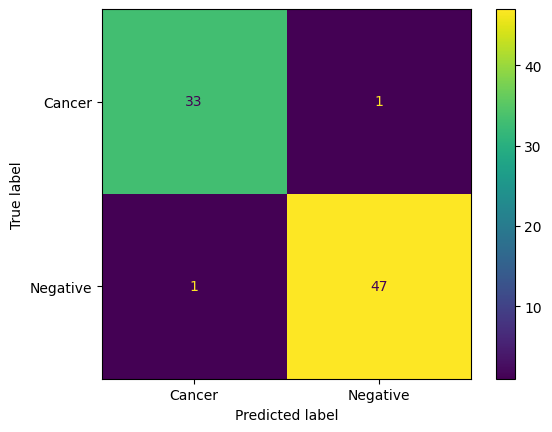

In [24]:
# Calculation y_true, y_pred -> # Bibliography: [Ref.24]
y_pred = np.array([])
y_true = np.array([])

for img, label in test_dataset:
    y_pred = np.concatenate([y_pred, np.argmax(model.predict(img), axis=1)]) # Bibliography: [Ref.25]
    y_true = np.concatenate([y_true, label.numpy()]) # Bibliography: [Ref.25]

conf_matrix = confusion_matrix(y_true, y_pred) # Bibliography: [Ref.26]
disp = ConfusionMatrixDisplay( # Bibliography: [Ref.27]
    confusion_matrix=conf_matrix,
    display_labels=classes
)
disp.plot()
plt.show()

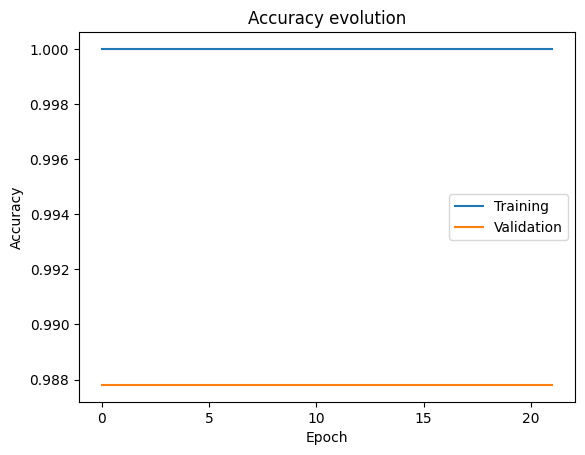

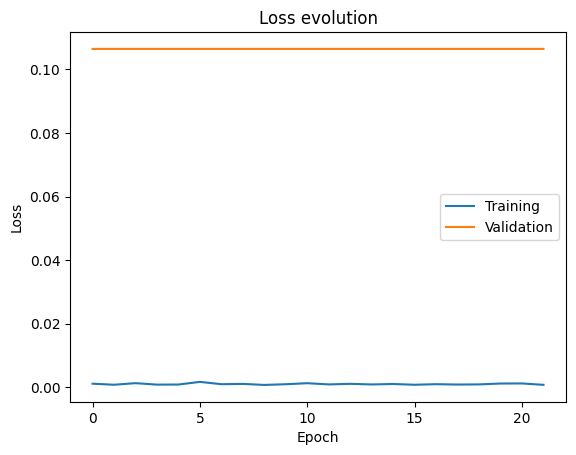

In [25]:
plt.figure()
plt.plot(train_hist.history["accuracy"]) # Bibliography: [Ref.28]
plt.plot(train_hist.history["val_accuracy"]) # Bibliography: [Ref.28]
plt.title("Accuracy evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.29]
plt.ylabel("Accuracy") # Bibliography: [Ref.30]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.31]
plt.show()

plt.figure()
plt.plot(train_hist.history["loss"]) # Bibliography: [Ref.28]
plt.plot(train_hist.history["val_loss"]) # Bibliography: [Ref.28]
plt.title("Loss evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.29]
plt.ylabel("Loss") # Bibliography: [Ref.30]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.31]
plt.show()

# Model exportation to onnx

In [33]:
# .keras to. onnx -> # Bibliography: [Ref.32]
model_keras = load_model("checkpoints/best_resnet.keras")
onnx_model, _ = tf2onnx.convert.from_keras(model_keras)
name_onnx = f"Exp1-{datetime.datetime.now().strftime("%d-%m-%Y")}-ResNet50.onnx" # Bibliography: [Ref.33]
onnx.save(onnx_model, name_onnx)

# Bibliography

<div style="background-color: #c3fac4; border-color: #dfb54; border-left: 5px solid #dfb5b4; padding: 0.5em;">

<strong>Citation style: ISO 690.<strong>

[Ref.1] -- <em>Python|os.path.join() method</em> [online][accessed: 15th November 2026]. Available at: <a href="https://www.geeksforgeeks.org/python/python-os-path-join-method/">https://www.geeksforgeeks.org/python/python-os-path-join-method/</a>

[Ref.2] -- <em>train_test_split</em> [online][accessed: 15th November 2026]. Available at: <a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html">https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html</a>

[Ref.3] -- <em>Sklearn train_test_split: Dividir datos para Machine Learning en Python</em> [online][accessed: 15th November 2026]. Available at: <a href="https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split">https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split</a>

[Ref.4] -- <em>Python: Create a Directory if it Doesn’t Exist</em> [online][accessed: 15th November 2026]. Available at: <a href="https://datagy.io/python-create-directory-if-doesnt-exist/">https://datagy.io/python-create-directory-if-doesnt-exist/</a>

[Ref.5] -- <em>How to empty an entire directory with Python?</em> [online][accessed: 15th November 2026]. Available at: <a href="https://www.tradingcode.net/python/empty-clear-directory/">https://www.tradingcode.net/python/empty-clear-directory/</a>

[Ref.6] -- <em>Python zip() Function</em> [online][accessed: 15th November 2026]. Available at: <a href="https://www.w3schools.com/python/ref_func_zip.asp">https://www.w3schools.com/python/ref_func_zip.asp</a>

[Ref.7] -- <em>How do I copy a file?</em> [online][accessed: 15th November 2026]. Available at: <a href="https://stackoverflow.com/questions/123198/how-do-i-copy-a-file">https://stackoverflow.com/questions/123198/how-do-i-copy-a-file</a>

[Ref.8] -- <em>Image data loading</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/data_loading/image/">https://keras.io/api/data_loading/image/</a>

[Ref.9] -- <em>Supercharge Your AI: ResNet50 Transfer Learning Unleashed</em> [online][accessed: 15th November 2026]. Available at: <a href="https://paravisionlab.co.in/blogs/resnet50-with-transfer-learning">https://paravisionlab.co.in/blogs/resnet50-with-transfer-learning</a>

[Ref.10] -- <em>Resnet50 Transfer Learning with tensorflow.keras version 2.4+</em> [online][accessed: 15th November 2026]. Available at: <a href="https://stackoverflow.com/questions/68082626/resnet50-transfer-learning-with-tensorflow-keras-version-2-4">https://stackoverflow.com/questions/68082626/resnet50-transfer-learning-with-tensorflow-keras-version-2-4</a>

[Ref.11] -- <em>Input object</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/input/">https://keras.io/api/layers/core_layers/input/</a>

[Ref.12] -- <em>GlobalAveragePooling2D layer</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/layers/pooling_layers/global_average_pooling2d/">https://keras.io/api/layers/pooling_layers/global_average_pooling2d/</a>

[Ref.13] -- <em>Dense layer</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/dense/">https://keras.io/api/layers/core_layers/dense/</a>

[Ref.14] -- <em>Dropout layer</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/layers/regularization_layers/dropout/">https://keras.io/api/layers/regularization_layers/dropout/</a>

[Ref.15] -- <em>The Model class</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/models/model/">https://keras.io/api/models/model/</a>

[Ref.16] -- <em>Adam</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/optimizers/adam/">https://keras.io/api/optimizers/adam/</a>

[Ref.17] -- <em>Model training APIs</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/models/model_training_apis/">https://keras.io/api/models/model_training_apis/</a>

[Ref.18] -- <em>Probabilistic losses</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class">https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class</a>

[Ref.19] -- <em>EarlyStopping</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/callbacks/early_stopping/">https://keras.io/api/callbacks/early_stopping/</a>

[Ref.20] -- <em>ModelCheckpoint</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/callbacks/model_checkpoint/">https://keras.io/api/callbacks/model_checkpoint/</a>

[Ref.21] -- <em>ReduceLROnPlateau</em> [online][accessed: 15th November 2026]. Available at: <a href="https://keras.io/api/callbacks/reduce_lr_on_plateau/">https://keras.io/api/callbacks/reduce_lr_on_plateau/</a>

[Ref.22] -- <em>Callback Ordering</em> [online][accessed: 15th November 2026]. Available at: <a href="https://theneuralbase.com/tensorflow/learn/beginner/callback-ordering/">https://theneuralbase.com/tensorflow/learn/beginner/callback-ordering/</a>

[Ref.23] -- <em>Difference between Keras model.evaluate() and model.predict()?</em> [online][accessed: 15th November 2026]. Available at: <a href="https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/">https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/</a>

[Ref.24] -- <em>How understand image_dataset_from_directory() and use it as X, y input?</em> [online][accessed: 15th November 2026]. Available at: <a href="https://stackoverflow.com/questions/67723065/how-understand-image-dataset-from-directory-and-use-it-as-x-y-input">https://stackoverflow.com/questions/67723065/how-understand-image-dataset-from-directory-and-use-it-as-x-y-input</a>

[Ref.25] -- <em>numpy.concatenate</em> [online][accessed: 15th November 2026]. Available at: <a href="https://numpy.org/doc/2.5/reference/generated/numpy.concatenate.html">https://numpy.org/doc/2.5/reference/generated/numpy.concatenate.html</a>

[Ref.26] -- <em>confusion_matrix</em> [online][accessed: 15th November 2026]. Available at: <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html</a>

[Ref.27] -- <em>ConfusionMatrixDisplay</em> [online][accessed: 15th November 2026]. Available at: <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html</a>

[Ref.28] -- <em>Display Deep Learning Model Training History in Keras</em> [online][accessed: 15th November 2026]. Available at: <a href="https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/">https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/</a>

[Ref.29] -- <em>matplotlib.pyplot.xlabel</em> [online][accessed: 15th November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html</a>

[Ref.30] -- <em>matplotlib.pyplot.ylabel</em> [online][accessed: 15th November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html</a>

[Ref.31] -- <em>matplotlib.pyplot.legend</em> [online][accessed: 15th November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html</a>

[Ref.32] -- <em>Convert trained Keras models (.h5) to ONNX format.</em> [online][accessed: 15th November 2026]. Available at: <a href="https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd">https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd</a>

[Ref.33] -- <em>Python Datetime</em> [online][accessed: 15th November 2026]. Available at: <a href="https://www.w3schools.com/python/python_datetime.asp">https://www.w3schools.com/python/python_datetime.asp</a>